Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 08 -- experiment: embeddings and the geometry of feature space

Companion material to [`lecture.en.md`](lecture.en.md). Three experiments:
(A) geometry on synthetic vectors -- euclidean vs cosine, L2 normalization,
k-NN; (B) Caltech101 (reused from module 07) -- raw pixels vs. ResNet18
features vs. normalized embeddings; (C) `nn.Embedding` as a learned table
of vectors.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_num_threads(4)  # BLAS thread stability under jupyter/ipykernel (lesson from module 07)
device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cpu


## A. Embedding geometry on synthetic vectors

### A.1 Euclidean vs. cosine similarity -- a worked example

In [2]:
def euclidean(a, b):
    return torch.norm(a - b)


def cosine(a, b):
    return (a @ b) / (a.norm() * b.norm())


q = torch.tensor([1.0, 0.0])
a = torch.tensor([10.0, 0.0])   # same direction as q, large norm
b = torch.tensor([0.9, 0.9])    # different direction, small norm

print(f"q={q.tolist()}")
for name, v in [("a", a), ("b", b)]:
    print(f"{name}={v.tolist()}  euclidean(q,{name})={euclidean(q, v):.4f}  "
          f"cosine(q,{name})={cosine(q, v):.4f}")

closer_euclidean = "a" if euclidean(q, a) < euclidean(q, b) else "b"
closer_cosine = "a" if cosine(q, a) > cosine(q, b) else "b"
print(f"\ncloser by euclidean: {closer_euclidean}")
print(f"closer by cosine:    {closer_cosine}")
assert closer_euclidean != closer_cosine, "expected different rankings"
print("\nOK: the two metrics give OPPOSITE rankings for the same query.")

q=[1.0, 0.0]
a=[10.0, 0.0]  euclidean(q,a)=9.0000  cosine(q,a)=1.0000
b=[0.8999999761581421, 0.8999999761581421]  euclidean(q,b)=0.9055  cosine(q,b)=0.7071

closer by euclidean: b
closer by cosine:    a

OK: the two metrics give OPPOSITE rankings for the same query.


### A.2 Identity for normalized vectors: $\|\hat a-\hat b\|_2^2 = 2-2\cos(\hat a,\hat b)$

In [3]:
torch.manual_seed(0)
max_diff = 0.0
for _ in range(1000):
    x = torch.randn(5)
    y = torch.randn(5)
    xu, yu = x / x.norm(), y / y.norm()
    lhs = (xu - yu).pow(2).sum()
    rhs = 2 - 2 * cosine(xu, yu)
    max_diff = max(max_diff, (lhs - rhs).abs().item())

print(f"max |lhs - rhs| over 1000 random vector pairs: {max_diff:.2e}")
assert max_diff < 1e-4
print("OK: the identity is confirmed within floating-point error.")

max |lhs - rhs| over 1000 random vector pairs: 7.15e-07
OK: the identity is confirmed within floating-point error.


### A.3 L2 normalization -- an edge case (the zero vector)

In [4]:
zero_vec = torch.zeros(5)
naive = zero_vec / zero_vec.norm()
print("naive normalization of the zero vector:", naive.tolist())
assert torch.isnan(naive).all()

eps = 1e-8
safe = zero_vec / (zero_vec.norm() + eps)
print("normalization with the safeguard (+eps):", safe.tolist())
assert not torch.isnan(safe).any()
print("\nOK: naive normalization gives NaN on the zero vector, the +eps version does not.")

naive normalization of the zero vector: [nan, nan, nan, nan, nan]
normalization with the safeguard (+eps): [0.0, 0.0, 0.0, 0.0, 0.0]

OK: naive normalization gives NaN on the zero vector, the +eps version does not.


### A.4 k-NN: a different ranking for euclidean and cosine on a larger set

In [5]:
torch.manual_seed(1)
N, dim = 20, 8
pool = torch.randn(N, dim)
pool[3] = pool[0] * 3.0 + torch.randn(dim) * 0.05   # same direction as pool[0], large norm
query2 = pool[0].clone()

dists = torch.norm(pool - query2, dim=1)
coss = (pool @ query2) / (pool.norm(dim=1) * query2.norm())

k = 5
euclid_top = dists.argsort()[1 : k + 1]       # [1:] skips itself (distance 0)
cosine_top = (-coss).argsort()[1 : k + 1]

print(f"Euclidean top-{k} (excluding the query):", euclid_top.tolist())
print(f"Cosine top-{k} (excluding the query):   ", cosine_top.tolist())
print(f"\nDifference in neighbor sets: "
      f"{set(euclid_top.tolist()) != set(cosine_top.tolist())}")

Euclidean top-5 (excluding the query): [9, 10, 18, 8, 2]
Cosine top-5 (excluding the query):    [3, 9, 7, 18, 17]

Difference in neighbor sets: True


## B. Caltech101: raw pixels vs. ResNet18 features vs. normalized embeddings

The same 10-class Caltech101 subset as in module 07 (zero new downloads --
the dataset and weights are already in the cache/`data/registry.yml`).

In [6]:
import contextlib
import io
import os

import torchvision.datasets as tvd
from PIL import Image
from torchvision.models import ResNet18_Weights, resnet18

_REPO_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "pyproject.toml").is_file()
    ),
    Path.cwd(),
)
DATA_CACHE_DIR = Path(
    os.environ.get("DEEP_LEARNING_DATA_CACHE", _REPO_ROOT / "data_cache")
).expanduser().resolve()

CLASSES = [
    "airplanes", "Motorbikes", "elephant", "kangaroo", "grand_piano",
    "car_side", "dalmatian", "butterfly", "starfish", "dolphin",
]
PER_CLASS = 30

weights = ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    full_ds = tvd.Caltech101(root=DATA_CACHE_DIR, download=True, target_type="category")
    resnet_model = resnet18(weights=weights)

class_to_label = {c: i for i, c in enumerate(CLASSES)}


def load_image(ds, idx):
    # Caltech101.__getitem__ unconditionally imports scipy (even for
    # target_type="category") -- we read the JPEG directly, as in module 07.
    path = os.path.join(
        ds.root, "101_ObjectCategories",
        ds.categories[ds.y[idx]], f"image_{ds.index[idx]:04d}.jpg",
    )
    return Image.open(path).convert("RGB")


selected_indices, selected_labels = [], []
counts = {c: 0 for c in CLASSES}
for idx, y_ in enumerate(full_ds.y):
    cat_name = full_ds.categories[y_]
    if cat_name in class_to_label and counts[cat_name] < PER_CLASS:
        selected_indices.append(idx)
        selected_labels.append(class_to_label[cat_name])
        counts[cat_name] += 1

imgs_tensor = torch.stack([preprocess(load_image(full_ds, idx)) for idx in selected_indices])
y = torch.tensor(selected_labels)
print(f"imgs_tensor={tuple(imgs_tensor.shape)}  (number of images: {len(y)}, {PER_CLASS}/class)")

imgs_tensor=(300, 3, 224, 224)  (number of images: 300, 30/class)


In [7]:
raw_pixels = imgs_tensor.flatten(1)
print(f"raw pixels: {tuple(raw_pixels.shape)}")

resnet_model.eval()
feat_extractor = nn.Sequential(*list(resnet_model.children())[:-1])  # without fc, up to avgpool

start = time.time()
with torch.inference_mode():
    features = feat_extractor(imgs_tensor).flatten(1)
extract_time = time.time() - start
print(f"ResNet18 features (avgpool): {tuple(features.shape)}  extraction time: {extract_time:.2f}s")

features_norm = features / features.norm(dim=1, keepdim=True)

print(f"\nfeature norm (unnormalized): min={features.norm(dim=1).min():.2f} "
      f"max={features.norm(dim=1).max():.2f} mean={features.norm(dim=1).mean():.2f} "
      f"std={features.norm(dim=1).std():.2f}")
print(f"raw pixel norm: min={raw_pixels.norm(dim=1).min():.1f} "
      f"max={raw_pixels.norm(dim=1).max():.1f} mean={raw_pixels.norm(dim=1).mean():.1f} "
      f"std={raw_pixels.norm(dim=1).std():.1f}")

raw pixels: (300, 150528)


ResNet18 features (avgpool): (300, 512)  extraction time: 3.59s

feature norm (unnormalized): min=21.29 max=40.76 mean=29.35 std=3.33
raw pixel norm: min=151.7 max=841.7 mean=504.9 std=155.3


### B.1 Do learned features give a more useful neighborhood than raw pixels?

We measure, we do not assume: for each image we check whether the majority
of its $5$ nearest neighbors (excluding itself) share its class label.

In [8]:
def knn_label_agreement(X, y, k=5, metric="euclidean"):
    N = X.shape[0]
    if metric == "euclidean":
        dists = torch.cdist(X, X)
        dists.fill_diagonal_(float("inf"))
        nn_idx = dists.argsort(dim=1)[:, :k]
    else:
        Xn = X / X.norm(dim=1, keepdim=True).clamp_min(1e-8)
        sims = Xn @ Xn.T
        sims.fill_diagonal_(-float("inf"))
        nn_idx = sims.argsort(dim=1, descending=True)[:, :k]

    correct = 0
    for i in range(N):
        majority = torch.mode(y[nn_idx[i]]).values
        if majority == y[i]:
            correct += 1
    return correct / N


print(f"{'representation':28s} {'euclidean':>10s} {'cosine':>10s}")
for name, X in [
    ("raw pixels", raw_pixels),
    ("ResNet18 features", features),
    ("L2-normalized features", features_norm),
]:
    acc_e = knn_label_agreement(X, y, k=5, metric="euclidean")
    acc_c = knn_label_agreement(X, y, k=5, metric="cosine")
    print(f"{name:28s} {acc_e:>10.3f} {acc_c:>10.3f}")

representation                euclidean     cosine
raw pixels                        0.433      0.520
ResNet18 features                 0.987      0.990
L2-normalized features            0.990      0.990


### B.2 A specific example: the same query, a different neighborhood

A query for which raw pixels give a **wrong** majority of neighbors, and
ResNet18 features give the **correct** one.

In [9]:
raw_n = raw_pixels / raw_pixels.norm(dim=1, keepdim=True).clamp_min(1e-8)
feat_n = features / features.norm(dim=1, keepdim=True).clamp_min(1e-8)

example_idx = None
for qi in range(len(y)):
    sims_raw = raw_n @ raw_n[qi]
    sims_raw[qi] = -float("inf")
    sims_feat = feat_n @ feat_n[qi]
    sims_feat[qi] = -float("inf")
    top5_raw = sims_raw.argsort(descending=True)[:5]
    top5_feat = sims_feat.argsort(descending=True)[:5]
    raw_majority = torch.mode(y[top5_raw]).values.item()
    feat_majority = torch.mode(y[top5_feat]).values.item()
    if raw_majority != y[qi].item() and feat_majority == y[qi].item():
        example_idx = qi
        print(f"query idx={qi}  true class={CLASSES[y[qi].item()]}")
        raw_names = [CLASSES[lbl] for lbl in y[top5_raw].tolist()]
        feat_names = [CLASSES[lbl] for lbl in y[top5_feat].tolist()]
        print(f"  raw pixels, top-5 neighbors:     {raw_names}")
        print(f"  ResNet18 features, top-5 neighbors: {feat_names}")
        break

assert example_idx is not None, "no example found (unexpected)"

query idx=25  true class=Motorbikes
  raw pixels, top-5 neighbors:     ['Motorbikes', 'airplanes', 'elephant', 'car_side', 'elephant']
  ResNet18 features, top-5 neighbors: ['Motorbikes', 'Motorbikes', 'Motorbikes', 'Motorbikes', 'Motorbikes']


## C. 2D PCA visualization

We project the $512$-dimensional features onto the $2$ directions of
largest variance (eigendecomposition of the covariance matrix,
`torch.linalg.eigh` -- verified earlier against the full-rank
`torch.pca_lowrank`).

variance explained by the first 2 directions: 19.6%


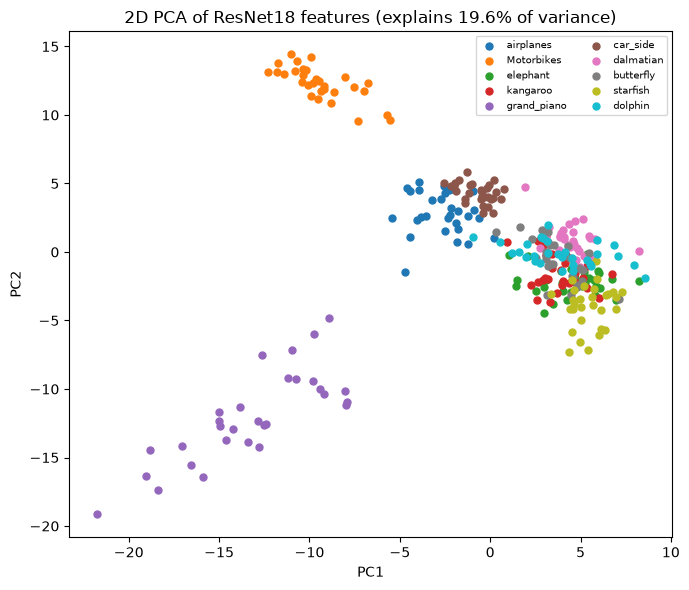


Interpretation note: these 2 directions explain only 19.6% of the total variance of the 512-dimensional features. Clusters visible (or not visible) here are NOT evidence of separation quality in the full space -- this is a projection onto the directions of LARGEST VARIANCE, not of the best class separability.


In [10]:
def pca_2d(X):
    mean = X.mean(dim=0)
    Xc = X - mean
    cov = (Xc.T @ Xc) / (X.shape[0] - 1)
    eigvals, eigvecs = torch.linalg.eigh(cov)
    idx = eigvals.argsort(descending=True)
    top2 = eigvecs[:, idx[:2]]
    proj = Xc @ top2
    explained = (eigvals[idx[:2]].sum() / eigvals.sum()).item()
    return proj, explained


proj, explained = pca_2d(features)
print(f"variance explained by the first 2 directions: {explained:.1%}")

fig, ax = plt.subplots(figsize=(7, 6))
cmap = plt.get_cmap("tab10")
for c in range(10):
    mask = y == c
    ax.scatter(proj[mask, 0], proj[mask, 1], label=CLASSES[c], color=cmap(c), s=25)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"2D PCA of ResNet18 features (explains {explained:.1%} of variance)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print(
    f"\nInterpretation note: these 2 directions explain only {explained:.1%} "
    "of the total variance of the 512-dimensional features. Clusters visible (or "
    "not visible) here are NOT evidence of separation quality in the full space -- "
    "this is a projection onto the directions of LARGEST VARIANCE, not of the best "
    "class separability."
)

## D. `nn.Embedding`: a learned table of vectors

A small, executable example: a few tokens, random initialization,
training, verification that only the rows actually used in the data get
updated.

In [11]:
VOCAB = ["cat", "dog", "car", "bike", "apple", "banana"]
token_to_id = {tok: i for i, tok in enumerate(VOCAB)}
V, d = len(VOCAB), 4

torch.manual_seed(0)
embedding = nn.Embedding(V, d)
print("embedding table BEFORE training (random, no structure):")
print(embedding.weight.detach())

before = embedding.weight.detach().clone()

# a simple "task": tokens 0,1 (cat, dog) -> label 0 (animals);
# tokens 2,3 (car, bike) -> label 1 (vehicles); tokens 4,5 never occur in the data
train_ids = torch.tensor([0, 1, 0, 1, 2, 3, 2, 3])
train_labels = torch.tensor([0, 0, 0, 0, 1, 1, 1, 1])

head = nn.Linear(d, 2)
opt = torch.optim.Adam(list(embedding.parameters()) + list(head.parameters()), lr=0.05)
loss_fn = nn.CrossEntropyLoss()
for _ in range(200):
    opt.zero_grad()
    vecs = embedding(train_ids)
    logits = head(vecs)
    loss = loss_fn(logits, train_labels)
    loss.backward()
    opt.step()

after = embedding.weight.detach().clone()
used_ids = {0, 1, 2, 3}
for i, tok in enumerate(VOCAB):
    changed = not torch.equal(before[i], after[i])
    status = "used in the data" if i in used_ids else "UNUSED"
    print(f"  {tok:10s} (id={i}, {status}): row changed = {changed}")
    assert changed == (i in used_ids), f"unexpected state for {tok}"

print("\nOK: only the rows of tokens that occurred in the training data changed.")

embedding table BEFORE training (random, no structure):
tensor([[-1.1258, -1.1524, -0.2506, -0.4339],
        [ 0.8487,  0.6920, -0.3160, -2.1152],
        [ 0.4681, -0.1577,  1.4437,  0.2660],
        [ 0.1665,  0.8744, -0.1435, -0.1116],
        [ 0.9318,  1.2590,  2.0050,  0.0537],
        [ 0.6181, -0.4128, -0.8411, -2.3160]])
  cat        (id=0, used in the data): row changed = True
  dog        (id=1, used in the data): row changed = True
  car        (id=2, used in the data): row changed = True
  bike       (id=3, used in the data): row changed = True
  apple      (id=4, UNUSED): row changed = False
  banana     (id=5, UNUSED): row changed = False

OK: only the rows of tokens that occurred in the training data changed.


## Summary

- Euclidean and cosine similarity can give **opposite** rankings --
  verified on a simple 2D example.
- For L2-normalized vectors, both rankings coincide (a mathematical
  identity, verified numerically), but normalizing the zero vector is
  undefined without the `+eps` safeguard.
- On Caltech101: ResNet18 features give a clearly more useful neighborhood
  (label agreement) than raw pixels -- measured, not assumed; a specific
  example shows the difference qualitatively, not just numerically.
- 2D PCA is a projection onto the directions of maximum variance -- the
  explained-variance percentage tells you how much to trust that
  projection.
- `nn.Embedding` updates only the rows actually present in the training
  data -- verified programmatically, not assumed.

Discussion questions and the bibliography: see [`lecture.en.md`](lecture.en.md).